## Blue Ridge 6LiF run October 2026 deposit SN04

This repeats the work of Run10_26_SN01 on the fourth deposit, SN04.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from DepositData5 import DepositData

In [2]:
sn04 = DepositData.from_file('Run10_26_SN04.txt', '6LiF on Si')

Using t1
Using t2
Using grading
Using roughness


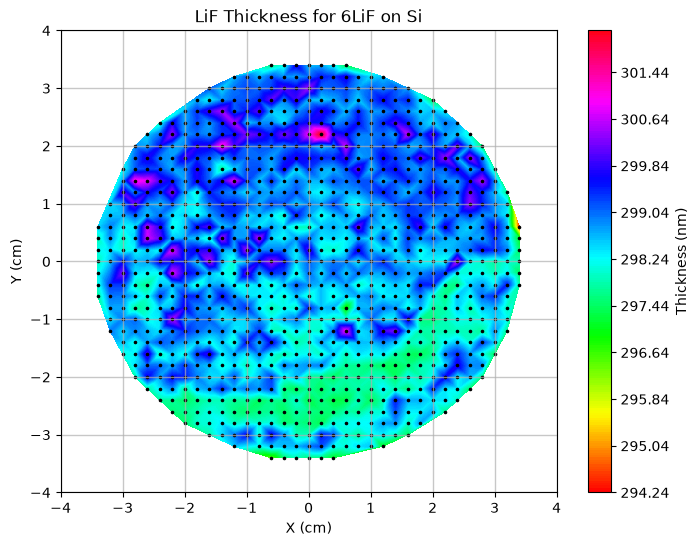

In [3]:
sn04.Ron_plot()

So at this point this is the worst, with a clear slope. Let's see when we account for the voids.

In [4]:
zc04 = sn04.t1 + 0.847 * sn04.t2

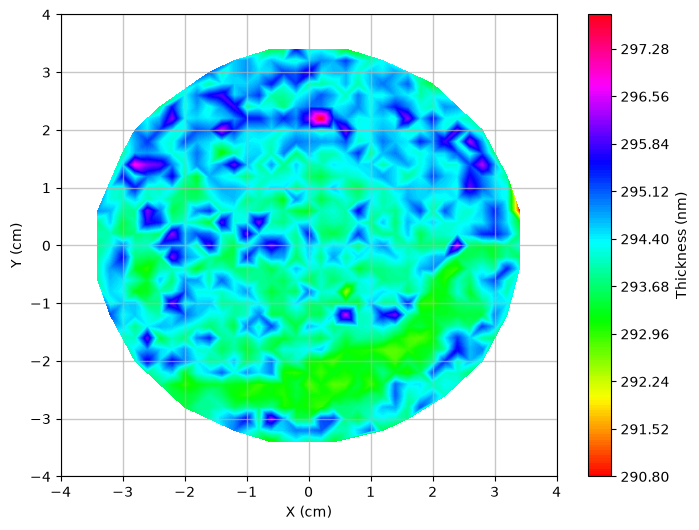

In [5]:
sn04.contour_plot(zc04)

Still looks to be a slight slope and one nasty hot sport on the edge of the active region. Though we think that these individual spots are probably not real.  

Try for the 3-D anyway.

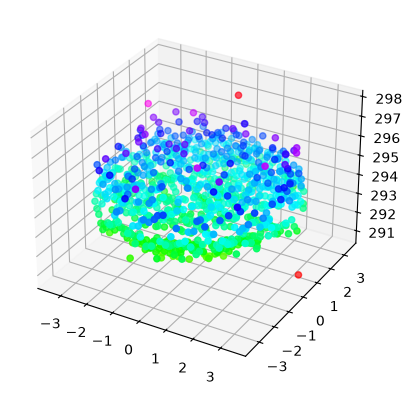

In [6]:
        fig, ax = plt.subplots(subplot_kw={"projection": "3d"})
        surf = ax.scatter(sn04.xdata[sn04.mask], sn04.ydata[sn04.mask], 
                          zc04[sn04.mask], c= zc04[sn04.mask],
                          cmap='hsv')


That looks flatter than I was expecting, though with those two distant outliers. 

Let's try a planar fit. First we have to replace the default zdata with our void corrected data.

In [7]:
sn04.zdata = zc04

In [8]:
# Scaled initial parameters
ipg = [ 5.96,  0.0, 0.0]

def planar_fit(p, a):
    return DepositData.fit_helper(p, a, 'angled_plane')

In [9]:
sn04f =sn04.fit_to(planar_fit, ipg)
print(sn04f)

  message: Optimization terminated successfully.
  success: True
   status: 0
      fun: 403.33918295640535
        x: [ 2.942e+02 -7.645e+00  1.495e-01]
      nit: 16
      jac: [ 0.000e+00 -6.866e-05  0.000e+00]
 hess_inv: [[ 5.322e-04  5.684e-06 -2.339e-07]
            [ 5.684e-06  8.041e-03 -3.429e-05]
            [-2.339e-07 -3.429e-05  1.774e-04]]
     nfev: 108
     njev: 27


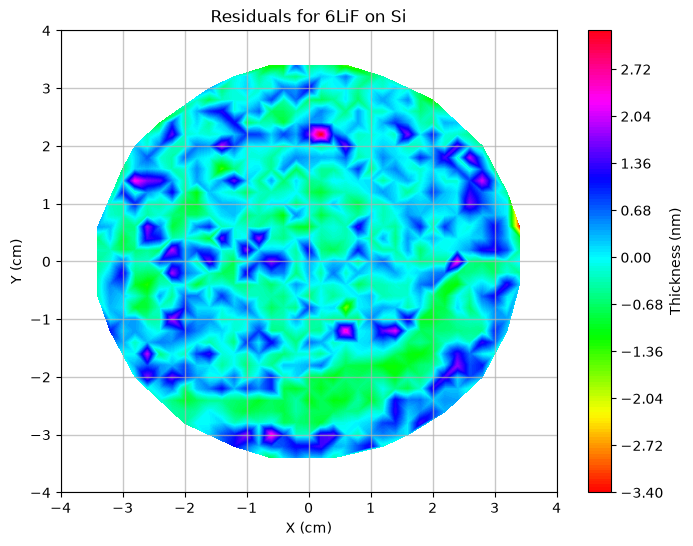

In [10]:
sn04.resid_plot()

Another pretty flat deposit. This time the slope si the highest that we have seen so again it is worth plotting the fit.

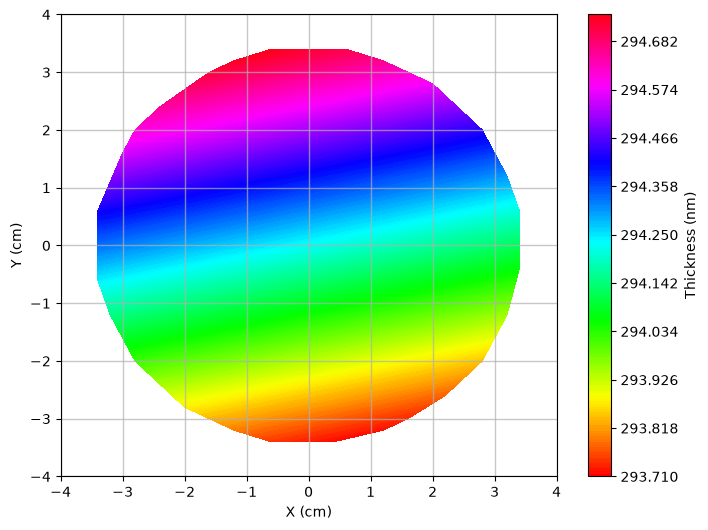

In [12]:
sn04.contour_plot(sn04.fit_z)

So not really any worse. We are still under 1 nm total thickness difference across the entire wafer.